# TPS · Módulo 1 — Contextualización y verificación del preprocesamiento
**PSIB 2026Q2 · Grupo 12** — Lautersztein, Reggio, Ballester
*Caracterización de la carga cognitiva mediante análisis espectral del EEG durante aritmética mental*

Este notebook cubre las etapas 1 a 3 del pipeline del anteproyecto:

1. **Contextualización**: qué hay en la base (sujetos, canales, fs, duración, amplitudes).
2. **Verificación del preprocesamiento**: con la PSD de Welch comprobamos si los filtros que declaran los autores (pasa-altos 0,5 Hz, pasa-bajos 45 Hz, notch 50 Hz) realmente están aplicados. Además **diseñamos un filtro FIR y uno IIR** para el mismo pasabanda y medimos cuánto cambiaría la señal si volviéramos a filtrar; con esa evidencia decidimos si hace falta.
3. **Segmentación temporal**: 60 s por condición, cortados en épocas de 4 s (las *realizaciones* del proceso), con un chequeo exploratorio de estacionariedad.

La salida (`modulo1_epocas.npz`) es la entrada del Módulo 2 (análisis de ritmos).

## 0. Instalación y descarga
Base: *EEG During Mental Arithmetic Tasks* (PhysioNet, `eegmat` v1.0.0). Son 36 sujetos × 2 archivos EDF:
`SubjectNN_1.edf` = **reposo** (ojos cerrados) y `SubjectNN_2.edf` = **cálculo mental** (restas seriadas).
`subject-info.csv` tiene la calidad de la cuenta de cada sujeto (1 = buen desempeño → grupo G, 0 = bajo → grupo B).

In [33]:
!pip -q install mne
# Descarga toda la base en la carpeta eegmat/ (-N: no vuelve a bajar lo que ya está)
!wget -q -r -N -c -np -nH --cut-dirs=3 -P eegmat https://physionet.org/files/eegmat/1.0.0/

import numpy as np, pandas as pd, matplotlib.pyplot as plt, mne
from scipy import signal
mne.set_log_level('ERROR')

## 1. Contextualización
### 1.1 Sujetos y grupos de desempeño

In [34]:

info = pd.read_csv('eegmat/subject-info.csv')

assert len(info) == 36, "La base debe contener 36 sujetos"
assert info['Subject'].is_unique, "Hay sujetos duplicados"
assert set(info['Subject']) == {
    f'Subject{i:02d}' for i in range(36)
}, "Faltan sujetos o existen identificadores inesperados"
assert info['Count quality'].notna().all()
assert set(info['Count quality'].unique()) <= {0, 1}

info['grupo'] = info['Count quality'].map({1: 'G', 0: 'B'})

print("Distribución de grupos:")
print(info['grupo'].value_counts())
print("Rango de edades:", info['Age'].min(), "-", info['Age'].max())
display(info.head())


Distribución de grupos:
grupo
G    26
B    10
Name: count, dtype: int64
Rango de edades: 16 - 26


,Subject,Age,Gender,Recording year,Number of subtractions,Count quality,grupo
0,Subject00,21,F,2011,9.70,0,B
1,Subject01,18,F,2011,29.35,1,G
2,Subject02,19,F,2012,12.88,1,G
3,Subject03,17,F,2010,31.00,1,G
4,Subject04,17,F,2010,8.60,0,B


### 1.2 Carga de los registros
Nos quedamos con los **19 canales del sistema 10-20** (descartamos la derivación A2-A1 y el ECG que también vienen en el EDF).
MNE devuelve la señal en voltios: la pasamos a **µV**, que es la escala habitual del EEG.

In [35]:
CANALES = ['Fp1', 'Fp2', 'F3', 'F4', 'F7', 'F8', 'Fz', 'C3', 'C4', 'Cz',
           'P3', 'P4', 'Pz', 'O1', 'O2', 'T3', 'T4', 'T5', 'T6']
COND = {1: 'reposo', 2: 'tarea'}

def cargar(sujeto, cond):
    """Lee un EDF y devuelve (datos [canales x muestras] en µV, fs) con los canales en el orden de CANALES."""
    raw = mne.io.read_raw_edf(f'eegmat/{sujeto}_{cond}.edf', preload=True)
    nombres = [c.replace('EEG', '').strip() for c in raw.ch_names]     # 'EEG Fp1' -> 'Fp1'
    idx = [nombres.index(c) for c in CANALES]
    return raw.get_data()[idx] * 1e6, raw.info['sfreq']

eeg = {(s, c): cargar(s, c) for s in info.Subject for c in COND}       # diccionario {(sujeto, condición): (x, fs)}

### 1.3 Montaje, frecuencia de muestreo, duración y amplitud
La tabla resume, por condición, la fs, la duración y dos medidas de amplitud: el **RMS** (nivel típico de la señal) y el **pico a pico máximo** entre canales (valores muy grandes sugieren artefactos residuales).

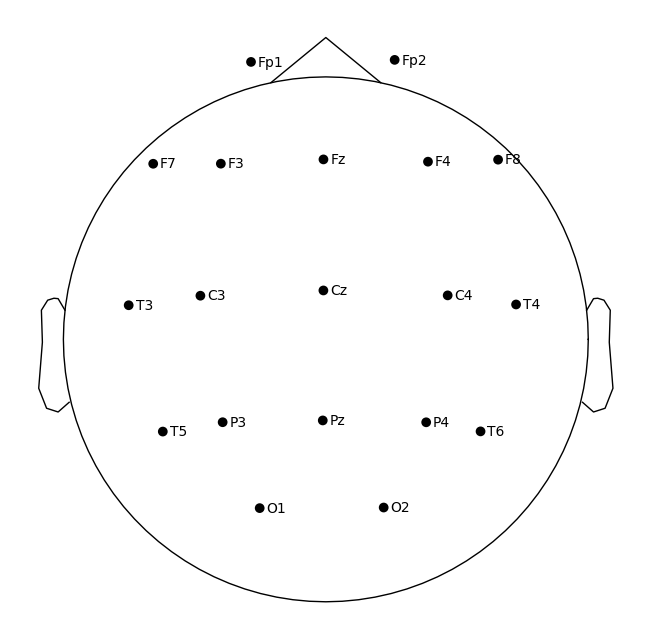

Encabezado EDF -> pasa-altos: 0.5 Hz · pasa-bajos: 45.0 Hz


fs               duracion_s               rms_uV               \
             min median    max        min median    max    min median   max   
condicion                                                                     
reposo     500.0  500.0  500.0       80.0  182.0  188.0    7.3   10.6  16.2   
tarea      500.0  500.0  500.0       62.0   62.0   62.0    6.3    9.7  15.5   

          ptp_max_uV                
                 min median    max  
condicion                           
reposo         107.9  161.5  695.9  
tarea           81.5  131.3  785.7

In [36]:
# Posición de los 19 electrodos en el sistema 10-20
info_mne = mne.create_info(CANALES, 500, 'eeg').set_montage('standard_1020')
mne.viz.plot_sensors(info_mne, show_names=True)

# Filtros declarados en el encabezado del EDF (el README dice "pasa-altos 30 Hz", que no coincide)
hdr = mne.io.read_raw_edf(f'eegmat/{info.Subject[0]}_1.edf').info
print(f"Encabezado EDF -> pasa-altos: {hdr['highpass']} Hz · pasa-bajos: {hdr['lowpass']} Hz")

ctx = pd.DataFrame([dict(sujeto=s, condicion=COND[c], fs=fs, duracion_s=x.shape[1] / fs,
                         rms_uV=x.std(axis=1).mean(), ptp_max_uV=np.ptp(x, axis=1).max())
                    for (s, c), (x, fs) in eeg.items()])
ctx.groupby('condicion')[['fs', 'duracion_s', 'rms_uV', 'ptp_max_uV']].agg(['min', 'median', 'max']).round(1)

### 1.4 Inspección visual de la señal
10 s de reposo y de tarea del mismo sujeto, con los canales desplazados verticalmente. Lo que buscamos: amplitudes razonables (decenas de µV), ausencia de saltos o canales planos, y a simple vista el ritmo alfa occipital (O1/O2) en reposo con ojos cerrados.

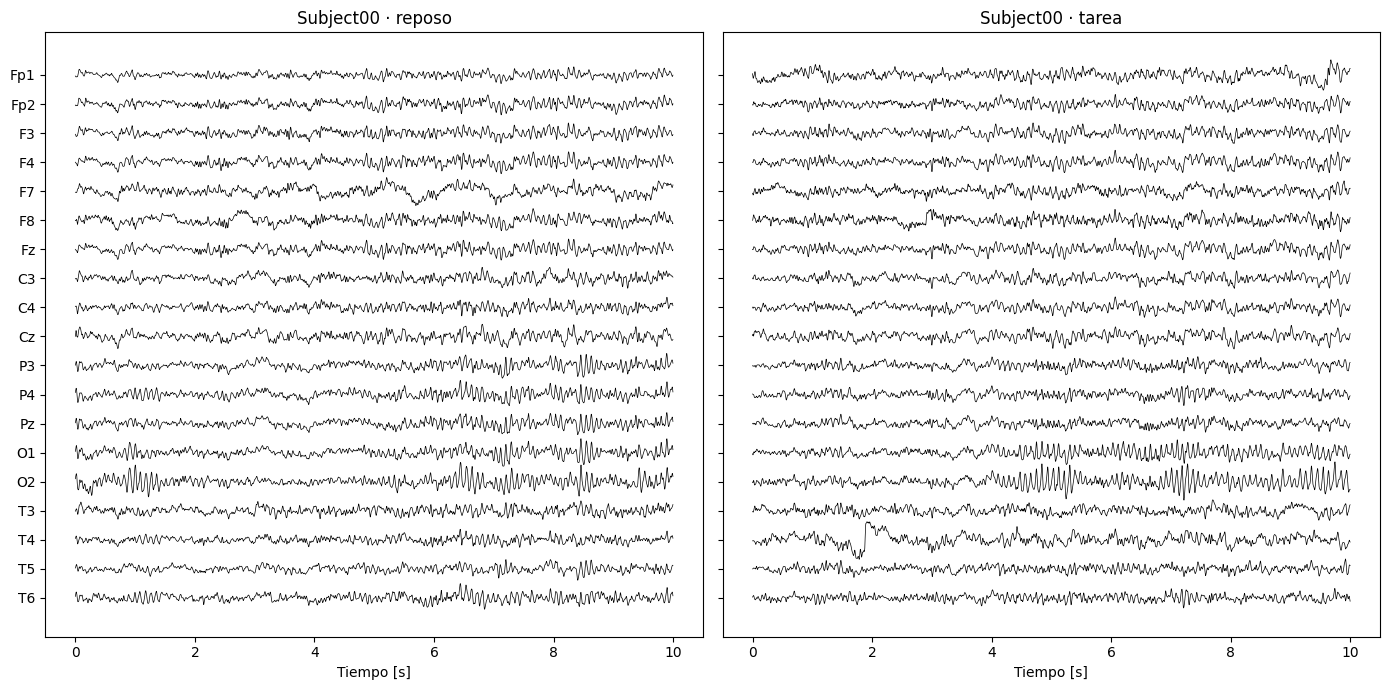

In [37]:
SUJ, T = info.Subject[0], 10                      # sujeto de ejemplo y segundos a graficar
fig, ax = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for a, c in zip(ax, COND):
    x, fs = eeg[SUJ, c]
    t = np.arange(int(T * fs)) / fs
    a.plot(t, x[:, :len(t)].T - 100 * np.arange(len(CANALES)), lw=0.5, color='k')   # 100 µV entre canales
    a.set(title=f'{SUJ} · {COND[c]}', xlabel='Tiempo [s]')
ax[0].set_yticks(-100 * np.arange(len(CANALES)), CANALES)
plt.tight_layout()

Pico a pico por canal (todos los sujetos). Los canales frontales (Fp1, Fp2, F7, F8) son los más expuestos a artefactos oculares y los temporales (T3–T6) a los musculares: si alguno se despega del resto es una pista de que el ICA de los autores no los eliminó por completo.

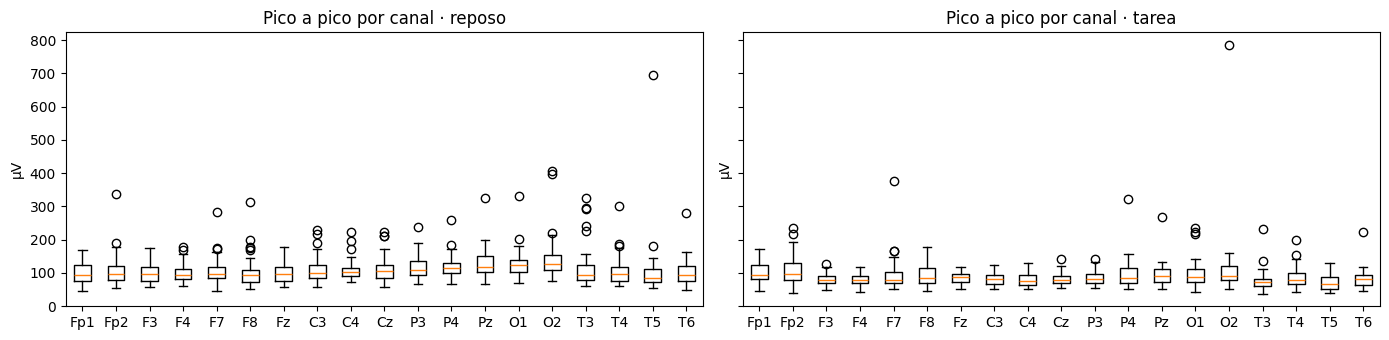

In [38]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5), sharey=True)
for a, c in zip(ax, COND):
    a.boxplot(np.array([np.ptp(x, axis=1) for (s, cc), (x, fs) in eeg.items() if cc == c]))   # [sujetos x canales]
    a.set_xticks(range(1, len(CANALES) + 1), CANALES)
    a.set(title=f'Pico a pico por canal · {COND[c]}', ylabel='µV')
plt.tight_layout()

## 2. Verificación del preprocesamiento
Estimamos la PSD con **Welch**: ventanas de Hamming con 50 % de solapamiento. Promediar los periodogramas de varias ventanas reduce la varianza del estimador, que es lo que necesitamos para ver la forma del espectro.

Para esta verificación usamos **ventanas de 8 s** (resolución Δf = 1/8 = 0,125 Hz). Con las ventanas de 2 s del análisis principal (Δf = 0,5 Hz) no hay ningún punto del espectro entre 0 y 0,5 Hz, y no se podría ver el pasa-altos. El costo es promediar menos ventanas (más varianza), pero se compensa porque además promediamos entre canales y sujetos.

Si los filtros declarados están aplicados deberíamos ver:
- caída de potencia **por debajo de 0,5 Hz** (pasa-altos),
- caída fuerte **por encima de 45 Hz** (pasa-bajos),
- **ningún pico en 50 Hz** (notch / interferencia de línea).

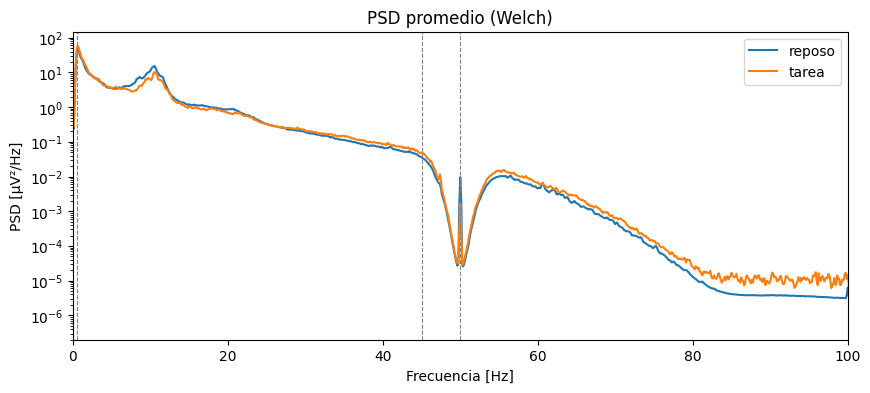

In [39]:
def psd_welch(x, fs, ventana_s=2):
    """PSD por Welch (Hamming, 50 % de solapamiento) sobre el último eje. Devuelve (f [Hz], PSD [µV²/Hz])."""
    n = int(ventana_s * fs)
    return signal.welch(x, fs, window='hamming', nperseg=n, noverlap=n // 2, axis=-1)

f = psd_welch(*eeg[SUJ, 1], ventana_s=8)[0]
psd = {c: np.array([psd_welch(*eeg[s, c], ventana_s=8)[1] for s in info.Subject]) for c in COND}   # [sujetos x canales x f]

fig, ax = plt.subplots(figsize=(10, 4))
for c in COND:
    ax.semilogy(f, psd[c].mean(axis=(0, 1)), label=COND[c])            # promedio entre sujetos y canales
for fc in (0.5, 45, 50):
    ax.axvline(fc, ls='--', c='gray', lw=0.8)
ax.set(xlabel='Frecuencia [Hz]', ylabel='PSD [µV²/Hz]', title='PSD promedio (Welch)', xlim=(0, 100))
ax.legend();

Para no depender sólo de la vista, cuantificamos tres indicadores por registro (en dB):
- **baja_dB**: potencia en 0,1–0,5 Hz respecto de 0,5–4 Hz → negativo si el pasa-altos actúa. Se excluye 0 Hz porque Welch le resta la media a cada ventana.
- **alta_dB**: potencia en 45–100 Hz respecto de 0,5–45 Hz → muy negativo si el pasa-bajos actúa.
- **pico50_dB**: PSD en 50 Hz respecto de la banda 40–45 Hz, justo antes de los filtros → muy negativo si el notch eliminó la interferencia de red.

In [40]:
# Densidad espectral media (µV²/Hz) en el intervalo [f1, f2).
# Se usa para comparar niveles espectrales, no potencia integrada.

banda = lambda P, f1, f2: P[..., (f >= f1) & (f < f2)].mean(axis=-1)
dB = lambda r: 10 * np.log10(r)

filas = []
for c in COND:
    P = psd[c].mean(axis=1)                                             # promedio entre canales -> [sujetos x f]
    filas.append(pd.DataFrame(dict(sujeto=info.Subject, condicion=COND[c],
        baja_dB=dB(banda(P, 0.1, 0.5) / banda(P, 0.5, 4)),
        alta_dB=dB(banda(P, 45, 100) / banda(P, 0.5, 45)),
        pico50_dB=dB(P[:, f == 50][:, 0] / banda(P, 40, 45)))))
ver = pd.concat(filas)
ver.groupby('condicion')[['baja_dB', 'alta_dB', 'pico50_dB']].agg(['mean', 'min', 'max']).round(1)

baja_dB            alta_dB             pico50_dB           
             mean   min  max    mean   min   max      mean   min  max
condicion                                                            
reposo       -5.4 -12.6 -2.6   -31.7 -39.0 -24.8     -17.4 -36.0  3.6
tarea        -6.0 -12.5 -0.3   -30.6 -38.3 -20.9     -24.1 -38.9 -8.3

PSD en dB por canal (promedio entre sujetos, reposo): sirve para detectar canales con exceso de baja frecuencia (oculares, frontales) o de alta frecuencia (musculares, temporales).

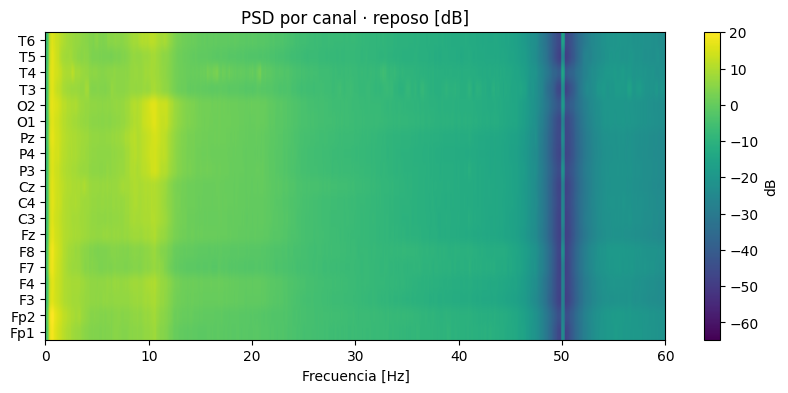

In [41]:
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(10 * np.log10(psd[1].mean(axis=0)), aspect='auto', origin='lower',
               extent=[f[0], f[-1], -0.5, len(CANALES) - 0.5], cmap='viridis')
ax.set(yticks=range(len(CANALES)), yticklabels=CANALES, xlim=(0, 60), xlabel='Frecuencia [Hz]', title='PSD por canal · reposo [dB]')
fig.colorbar(im, label='dB');

### 2.1 Diseño de filtros: FIR vs. IIR
Para decidir con datos si conviene volver a filtrar, diseñamos dos pasabanda **0,5–45 Hz** (la misma banda que declaran los autores) y medimos cuánto cambiarían la PSD:

- **FIR por ventana de Kaiser**: `kaiserord` da el número de coeficientes necesario para 60 dB de atenuación con una transición de 0,5 Hz. Es de **fase lineal** (coeficientes simétricos), así que basta con compensar su retardo de (N−1)/2 muestras para que no desplace la señal (convolución `mode='same'`).
- **IIR Butterworth de orden 4**: respuesta plana en la banda de paso. Su fase no es lineal, por eso se aplica **ida y vuelta** (`sosfiltfilt`), que cancela la fase y eleva al cuadrado la magnitud (fase cero, orden efectivo 8). Se implementa en secciones de segundo orden (SOS) para que sea numéricamente estable con un corte tan bajo (0,5 Hz a 500 Hz de muestreo).

El contraste es la idea central: para el mismo corte de 0,5 Hz el FIR necesita **miles de coeficientes** y el IIR sólo **8 polos**. Estas funciones se reutilizan en el análisis de sensibilidad (Módulo 4).

FIR: 3627 coeficientes (retardo compensado: 3.6 s) · IIR: 8 polos


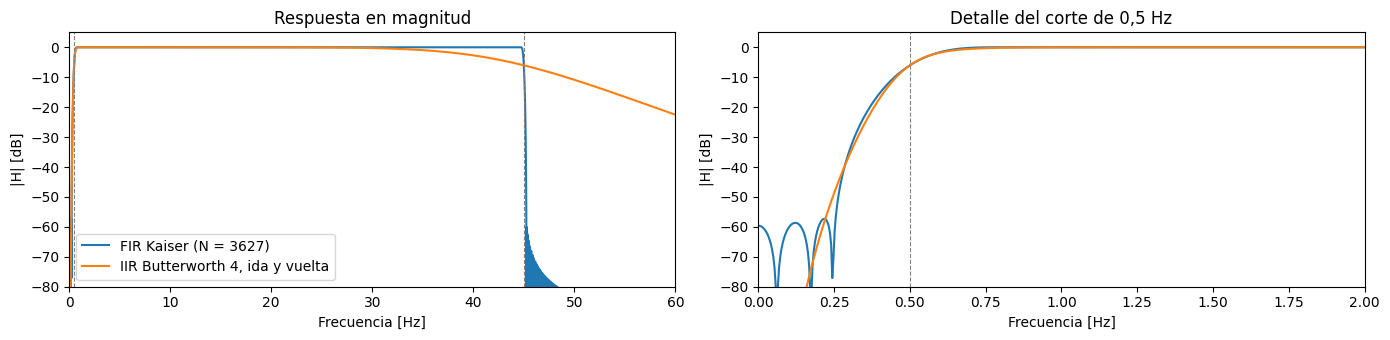

In [42]:
def filtro_fir(f1=0.5, f2=45, fs=500, aten_dB=60, transicion_hz=0.5):
    """Pasabanda FIR por ventana de Kaiser: kaiserord da N y beta para la atenuación y la transición pedidas."""
    n, beta = signal.kaiserord(aten_dB, transicion_hz / (fs / 2))
    n += 1 - n % 2                                                        # N impar -> FIR tipo I (retardo entero)
    return signal.firwin(n, [f1, f2], window=('kaiser', beta), pass_zero=False, fs=fs)

def filtro_iir(f1=0.5, f2=45, fs=500, orden=4):
    """Pasabanda Butterworth en secciones de segundo orden (SOS)."""
    return signal.butter(orden, [f1, f2], btype='bandpass', fs=fs, output='sos')

def aplicar(x, fir=None, sos=None):
    """Filtrado de fase cero sobre el último eje: FIR centrado (compensa el retardo) o IIR ida y vuelta."""
    if fir is not None:
        return signal.oaconvolve(x, fir[None], mode='same', axes=-1)
    return signal.sosfiltfilt(sos, x, axis=-1)

FS = eeg[SUJ, 1][1]
fir, sos = filtro_fir(fs=FS), filtro_iir(fs=FS)
print(f'FIR: {len(fir)} coeficientes (retardo compensado: {(len(fir) - 1) / 2 / FS:.1f} s) · IIR: {2 * len(sos)} polos')

# Respuesta en frecuencia (magnitud efectiva: |H| para el FIR centrado, |H|² para el IIR ida y vuelta)
fh, H_fir = signal.freqz(fir, worN=2 ** 16, fs=FS)
_, H_iir = signal.sosfreqz(sos, worN=2 ** 16, fs=FS)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for a, lim in zip(ax, [(0, 60), (0, 2)]):
    a.plot(fh, 20 * np.log10(np.abs(H_fir) + 1e-12), label=f'FIR Kaiser (N = {len(fir)})')
    a.plot(fh, 40 * np.log10(np.abs(H_iir) + 1e-12), label='IIR Butterworth 4, ida y vuelta')
    a.set(xlim=lim, ylim=(-80, 5), xlabel='Frecuencia [Hz]', ylabel='|H| [dB]')
    a.axvline(0.5, ls='--', c='gray', lw=0.8); a.axvline(45, ls='--', c='gray', lw=0.8)
ax[0].set_title('Respuesta en magnitud'); ax[1].set_title('Detalle del corte de 0,5 Hz')
ax[0].legend()
plt.tight_layout()

**¿Cuánto cambia la señal si la volvemos a filtrar?** Aplicamos los dos filtros a los 72 registros y comparamos la PSD (Welch, ventanas de 2 s) antes y después, en la banda que se analiza (1–30 Hz). Si el cambio es mínimo, re-filtrar no aporta nada.

In [43]:
def cambio_dB(x, x_filt):
    """Cambio medio |ΔPSD| en dB en 1-30 Hz (promedio entre canales y frecuencias)."""
    f2, P = psd_welch(np.stack([x, x_filt]), FS)
    m = (f2 >= 1) & (f2 <= 30)
    return np.abs(10 * np.log10(P[1][:, m] / P[0][:, m])).mean()

cambios = pd.DataFrame([dict(sujeto=s, condicion=COND[c],
                             FIR=cambio_dB(x, aplicar(x, fir=fir)), IIR=cambio_dB(x, aplicar(x, sos=sos)))
                        for (s, c), (x, fs) in eeg.items()])
cambios[['FIR', 'IIR']].describe().loc[['mean', '50%', 'max']].round(3)

,FIR,IIR
mean,0.006,0.037
50%,0.006,0.038
max,0.012,0.043


### Resultado de la verificación y decisión sobre el filtrado
*(Corrida sobre los 36 sujetos.)*

- **Pasa-altos 0,5 Hz: Los resultados son compatibles con el pasa-altos declarado y el encabezado EDF informa 0,5 Hz** La potencia en 0,1–0,5 Hz está en promedio 5–6 dB por debajo de la de 0,5–4 Hz. La atenuación observada es compatible con el filtrado pasa-altos declarado, aunque no permite determinar su orden con precisión

- **Pasa-bajos 45 Hz: La información del encabezado EDF y la atenuación espectral son compatibles con el pasa-bajos de 45 Hz declarado** Por encima de 45 Hz la potencia cae ~31 dB respecto de la banda útil. La caída más profunda (≈ 47–53 Hz) es la del notch. Entre 55 y 70 Hz queda algo de potencia (pasa-bajos de orden bajo), pero está fuera de las bandas que se analizan (hasta 30 Hz).

- **Notch 50 Hz: funciona en casi todos los registros.** En promedio, 50 Hz queda 17–24 dB por debajo de la banda 40–45 Hz. En el reposo de 2 sujetos (Subject12 y Subject22) queda un residuo de red del mismo nivel que esa banda. Como 50 Hz está fuera de las bandas de interés, no afecta las potencias por banda.

- **Filtros diseñados (sección 2.1):** el FIR de Kaiser necesita 3627 coeficientes para el corte de 0,5 Hz, mientras que el Butterworth utiliza 8 polos y presenta una respuesta en magnitud diferente de la del FIR. Volver a filtrar los 72 registros cambia la PSD en 1–30 Hz en promedio **0,006 dB con el FIR y 0,04 dB con el IIR** (máximo 0,04 dB): Los cambios espectrales medios fueron pequeños en el intervalo de 1–30 Hz evaluado.

- **Decisión: no se vuelve a filtrar.** La señal ya está limitada a 0,5–45 Hz, y un segundo filtrado no cambia la PSD en las bandas de interés; sólo agregaría cómputo y transitorios en los bordes. Los dos filtros quedan definidos para el análisis de sensibilidad del Módulo 4.

- **Filtros óptimos (Wiener):** no se aplican, porque necesitarían una referencia del ruido o de la señal limpia.

- Ya en esta etapa se ve el efecto esperado: el **pico alfa (~10 Hz) es más alto en reposo que durante la tarea.**

- Como el ICA no puede replicarse en el TP, en el informe se discute qué se habría visto sin él: artefactos oculares inflando delta y theta frontales, y musculares inflando beta temporal.

## 3. Segmentación temporal
- El reposo dura más que la tarea: para que ambas condiciones tengan **igual duración** tomamos **60 s por condición** (en el reposo, los últimos 60 s, los más cercanos en el tiempo a la tarea).
- Esos 60 s se cortan en **épocas de 4 s sin solapamiento** → 15 realizaciones por canal, cada una lo bastante corta para considerarla aproximadamente estacionaria.
- **Evaluación exploratoria de estacionariedad y variabilidad temporal**

  Las señales se dividen en épocas de 4 segundos sin solapamiento. Para caracterizar su estabilidad temporal, se calculan la media y la varianza de cada época y canal, evaluando sus variaciones a lo largo del registro.

  Adicionalmente, se identifican épocas con incrementos elevados de varianza respecto de la distribución temporal del mismo canal. Como criterio exploratorio, se marcan aquellas cuya varianza supera tres veces la mediana de las varianzas del canal correspondiente. Una época se considera marcada si al menos un canal cumple esta condición.

  Este procedimiento permite localizar segmentos que requieren una inspección adicional, pero no constituye una detección validada de artefactos ni una prueba formal de estacionariedad. Por lo tanto, las épocas marcadas se conservan en el conjunto de datos y no se excluyen automáticamente del análisis espectral posterior.

In [44]:
DUR_SEG, DUR_EPOCA = 60, 4     # segundos

def segmentar(x, fs):
    """Últimos DUR_SEG s del registro cortados en épocas de DUR_EPOCA s -> [épocas x canales x muestras]."""
    x, m = x[:, -int(DUR_SEG * fs):], int(DUR_EPOCA * fs)
    k = x.shape[1] // m                                   # cantidad de épocas completas
    return x[:, :k * m].reshape(len(x), k, m).transpose(1, 0, 2)

epocas = {(s, c): segmentar(*eeg[s, c]) for s, c in eeg}


# Estadísticos por época y canal
medias = {
    k: ep.mean(axis=-1)
    for k, ep in epocas.items()
}

var = {
    k: ep.var(axis=-1)
    for k, ep in epocas.items()
}

# Detección exploratoria de épocas con varianza elevada
atipica = {
    k: (v > 3 * np.median(v, axis=0)).any(axis=1)
    for k, v in var.items()
}

# Resumen de variabilidad temporal
est = pd.DataFrame([
    dict(
        sujeto=s,
        condicion=COND[c],
        n_epocas=len(v),
        variacion_media_uV=medias[s, c].std(axis=0).mean(),
        cv_varianza=(v.std(axis=0) / v.mean(axis=0)).mean(),
        epocas_atipicas=atipica[s, c].sum()
    )
    for (s, c), v in var.items()
])

print(
    f"Épocas marcadas: "
    f"{np.mean(np.concatenate(list(atipica.values()))):.1%}"
)

display(
    est.groupby('condicion')[
        ['n_epocas', 'variacion_media_uV',
         'cv_varianza', 'epocas_atipicas']
    ].agg(['mean', 'min', 'max']).round(2)
)


Épocas marcadas: 10.3%


n_epocas         variacion_media_uV             cv_varianza        \
              mean min max               mean   min   max        mean   min   
condicion                                                                     
reposo        15.0  15  15               0.64  0.38  1.96        0.39  0.25   
tarea         15.0  15  15               0.59  0.32  1.87        0.36  0.21   

                epocas_atipicas          
            max            mean min max  
condicion                                
reposo     0.95            1.58   0   5  
tarea      0.63            1.50   0   7

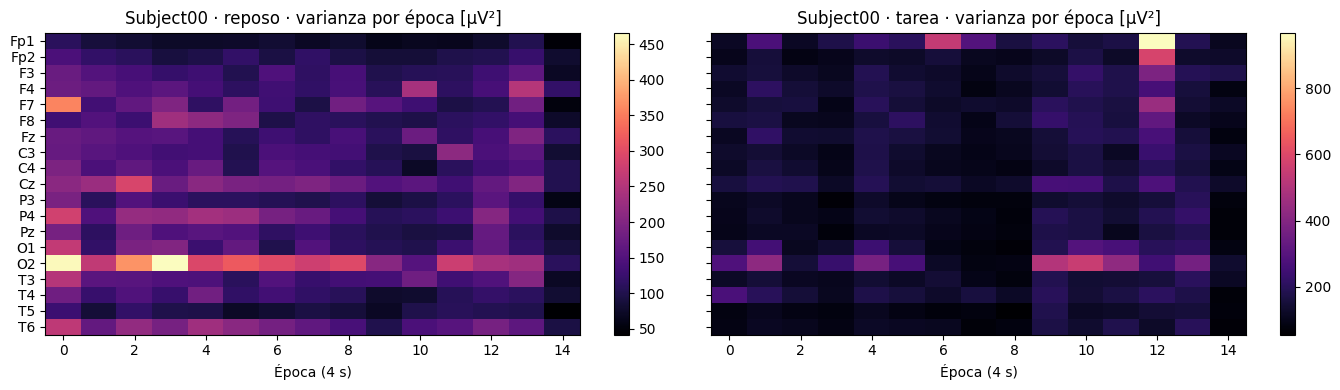

In [45]:
# Varianza por época y canal del sujeto de ejemplo: una época que "se enciende" en muchos canales es un cambio abrupto
fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, c in zip(ax, COND):
    im = a.imshow(var[SUJ, c].T, aspect='auto', cmap='magma')                # [canales x épocas]
    a.set(title=f'{SUJ} · {COND[c]} · varianza por época [µV²]', xlabel='Época (4 s)', yticks=range(len(CANALES)), yticklabels=CANALES)
    fig.colorbar(im, ax=a)
plt.tight_layout()

## 4. Guardado para el Módulo 2
Se guardan las épocas de cada sujeto y condición, las marcas exploratorias de épocas con varianza elevada y la tabla de sujetos. Las marcas permiten realizar controles de calidad posteriores, pero no implican la exclusión automática de los segmentos.
En Colab los archivos se borran al cerrar la sesión: para conservarlos, montar Drive (`from google.colab import drive; drive.mount('/content/drive')`) y cambiar la ruta.

In [46]:
np.savez_compressed('modulo1_epocas.npz', canales=CANALES, fs=eeg[SUJ, 1][1],
                    **{f'{s}_{COND[c]}': ep for (s, c), ep in epocas.items()},
                    **{f'{s}_{COND[c]}_atipicas': a for (s, c), a in atipica.items()})
info.to_csv('modulo1_sujetos.csv', index=False)

## 5. Conclusiones del Módulo 1
*(Corrida sobre los 36 sujetos.)*

**Base de datos**
- 36 sujetos, 19 canales del 10-20, fs = 500 Hz en todos los registros. El encabezado EDF confirma el filtrado 0,5–45 Hz. El README dice "pasa-altos de 30 Hz", que es un error.
- **Grupos de desempeño:** según `subject-info.csv` hay **26 sujetos G y 10 B**, no 24 y 12 como dicen el README y el anteproyecto. Se usa lo que figura en el archivo, y hay que corregir el número en el informe.
- **Duraciones:** reposo ≈ 182 s y tarea 62 s. Un sujeto (Subject31) tiene sólo 80 s de reposo. Todos tienen al menos 60 s, así que la segmentación es pareja para todos.
- **Amplitud:** RMS típico ~10 µV. En 6 sujetos hay canales con picos > 300 µV (máximo ~790 µV), que son artefactos residuales puntuales.

**Preprocesamiento:** los filtros declarados están aplicados, la información del encabezado y la distribución espectral respaldan la existencia del preprocesamiento declarado, aunque no permiten reconstruir exactamente su respuesta (pasa-altos 0,5 Hz: −5 a −6 dB en 0,1–0,5 Hz; pasa-bajos 45 Hz: −31 dB por encima; notch: 50 Hz entre 17 y 24 dB por debajo de 40–45 Hz). Un FIR (Kaiser, 3627 coeficientes) y un IIR (Butterworth 4, ida y vuelta) diseñados para la misma banda cambian la PSD menos de 0,05 dB, así que no se re-filtra.

**Segmentación y estacionariedad**
- 60 s por condición → 15 épocas de 4 s por registro.

- El análisis exploratorio de las épocas mostró variaciones temporales de la media y la varianza. El coeficiente de variación medio de las varianzas fue aproximadamente 0,39 en reposo y 0,36 durante la tarea, lo que evidencia variabilidad entre segmentos. Estos resultados no permiten demostrar estacionariedad estricta, pero aportan información sobre la estabilidad temporal de los registros. La estimación espectral mediante Welch resulta adecuada para reducir la variabilidad del estimador a través del promedio de periodogramas modificados.

- El 10,3 % de las épocas cumple el criterio exploratorio de varianza elevada, equivalente a aproximadamente 1,5 épocas por registro. Estas épocas se conservan y se identifican mediante marcas para permitir controles de calidad posteriores. El criterio utilizado no constituye una detección validada de artefactos y, por lo tanto, no justifica su exclusión automática del análisis espectral principal.